In [1]:
import csv
import json
import math
import os
import random
import warnings
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

warnings.filterwarnings("ignore")
# os.chdir(r"C:\你的專案資料夾")   # Data Preparation 的上一層

# ================================================================ 實驗設定
# "" = 原本的切法；"_m0.5" = 03split_npy.py 用 MARGIN = 0.5 切出來的寬鬆版本 (實驗 3)
# 每個實驗的 data / checkpoints / predictions 各自分開，不會互相覆蓋
EXP_TAG = "_m0.5"

# ================================================================ 路徑設定
LABEL_DIR = Path(r"..\Data Preparation\Phase5-Pause\output\03labels" + EXP_TAG)
SEG_DIR = Path(r"..\Data Preparation\Phase5-Pause\output\03segments" + EXP_TAG)
DATA_DIR = Path(r"data" + EXP_TAG)
CKPT_DIR = Path(r"checkpoints" + EXP_TAG)
PRED_DIR = Path(r"predictions" + EXP_TAG)

# ================================================================ 資料集切分
SPLIT = (0.8, 0.1, 0.1)    # train / val / test (以子資料夾 = 原始影片為單位)
SEED = 42
SPECIALS = ["<pad>", "<bos>", "<eos>", "<unk>"]
FLAG_DIMS = [126, 127, 155]   # 存在旗標，不做標準化
MIN_FREQ = 2               # 訓練集中出現少於幾次的字當作 <unk>

# ================================================================ 資料設定
FRAME_STRIDE = 2           # 每幾幀取 1 幀
MAX_FRAMES = 300           # 取樣後最多幾幀
MAX_TEXT_LEN = 64          # 含 <bos> <eos> 最多幾個字
SPEED_RANGE = (0.8, 1.2)   # 訓練時隨機變速
NOISE_STD = 0.05           # 訓練時加的雜訊

# ================================================================ 模型設定
D_MODEL = 256
N_HEADS = 4
ENC_LAYERS = 4
DEC_LAYERS = 3
FF_DIM = 1024
DROPOUT = 0.3

# ================================================================ 訓練設定
BATCH_SIZE = 32
EPOCHS = 150
LR = 3e-4
WEIGHT_DECAY = 0.05
WARMUP_EPOCHS = 5
LABEL_SMOOTHING = 0.1
PATIENCE = 10              # val loss 連續幾個 epoch 沒進步就停止
VAL_CER_EVERY = 5          # 每幾個 epoch 算一次驗證集 CER (只當參考)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
PAD, BOS, EOS, UNK = 0, 1, 2, 3
print("device:", DEVICE)

device: cuda


## DATASET

In [2]:
# {"<part>/<子資料夾>": [(分段路徑, 文字), ...]}
groups = {}
for txt in sorted(LABEL_DIR.glob("*/*/*.txt")):
    group = txt.parent.relative_to(LABEL_DIR)
    for line in txt.read_text(encoding="utf-8").splitlines():
        name, _, text = line.partition(": ")
        if text.strip():
            groups.setdefault(group.as_posix(), []).append(((group / f"{name}.npy").as_posix(), text.strip()))

keys = sorted(groups)
random.Random(SEED).shuffle(keys)
n_train, n_val = round(len(keys) * SPLIT[0]), round(len(keys) * SPLIT[1])
splits = {"train": keys[:n_train], "val": keys[n_train:n_train + n_val], "test": keys[n_train + n_val:]}

DATA_DIR.mkdir(parents=True, exist_ok=True)
rows = {}
for split, split_keys in splits.items():
    rows[split] = [row for key in sorted(split_keys) for row in groups[key]]
    with (DATA_DIR / f"{split}.csv").open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.writer(f)
        writer.writerow(("path", "text"))
        writer.writerows(rows[split])

from collections import Counter

freq = Counter(c for _, text in rows["train"] for c in text)
chars = sorted(c for c, n in freq.items() if n >= MIN_FREQ)
coverage = sum(freq[c] for c in chars) / sum(freq.values())
print(f"出現 {MIN_FREQ} 次以上的字：{len(chars)} / {len(freq)} 個，涵蓋訓練集 {coverage:.1%} 的字")
(DATA_DIR / "vocab.json").write_text(json.dumps(SPECIALS + chars, ensure_ascii=False), encoding="utf-8")

total, total_sq, count = np.zeros(156), np.zeros(156), 0
for path, _ in tqdm(rows["train"], desc="norm"):
    arr = np.load(SEG_DIR / path).astype(np.float64)
    total += arr.sum(0)
    total_sq += (arr ** 2).sum(0)
    count += len(arr)
mean = total / count
std = np.sqrt(np.maximum(total_sq / count - mean ** 2, 0)) + 1e-6
mean[FLAG_DIMS], std[FLAG_DIMS] = 0.0, 1.0
np.savez(DATA_DIR / "norm.npz", mean=mean.astype(np.float32), std=std.astype(np.float32))

for split in splits:
    print(f"{split}: {len(rows[split])} 句 ({len(splits[split])} 支影片)")
print(f"字元數: {len(chars)}")

出現 2 次以上的字：2662 / 3120 個，涵蓋訓練集 99.8% 的字


norm: 100%|██████████| 17901/17901 [00:40<00:00, 444.84it/s] 

train: 17901 句 (207 支影片)
val: 2234 句 (26 支影片)
test: 2265 句 (26 支影片)
字元數: 2662


In [3]:
def load_vocab():
    return json.loads((DATA_DIR / "vocab.json").read_text(encoding="utf-8"))


class SignDataset(Dataset):
    def __init__(self, split, vocab, train=False):
        with (DATA_DIR / f"{split}.csv").open(encoding="utf-8-sig", newline="") as f:
            self.rows = [(row["path"], row["text"]) for row in csv.DictReader(f)]
        self.stoi = {c: i for i, c in enumerate(vocab)}
        norm = np.load(DATA_DIR / "norm.npz")
        self.mean, self.std = norm["mean"], norm["std"]
        self.train = train
        # 一開始就把所有 .npy 讀進記憶體 (已標準化、已取樣)，訓練時不用再讀硬碟
        self.cache = [
            np.ascontiguousarray(((np.load(SEG_DIR / path).astype(np.float32) - self.mean) / self.std)[::FRAME_STRIDE])
            for path, _ in tqdm(self.rows, desc=f"load {split}")
        ]

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        text = self.rows[i][1]
        x = self.cache[i]
        if self.train:
            n = max(1, round(len(x) * random.uniform(*SPEED_RANGE)))
            x = x[np.linspace(0, len(x) - 1, n).round().astype(int)]
            x = x + np.random.normal(0, NOISE_STD, x.shape).astype(np.float32)
        x = x[:MAX_FRAMES]
        ids = [BOS] + [self.stoi.get(c, UNK) for c in text[:MAX_TEXT_LEN - 2]] + [EOS]
        return torch.from_numpy(np.ascontiguousarray(x)), torch.tensor(ids)


def collate(batch):
    xs, ys = zip(*batch)
    src = nn.utils.rnn.pad_sequence(xs, batch_first=True)
    lengths = torch.tensor([len(x) for x in xs])
    src_mask = torch.arange(src.size(1))[None, :] >= lengths[:, None]     # True = padding
    tgt = nn.utils.rnn.pad_sequence(ys, batch_first=True, padding_value=PAD)
    return src, src_mask, tgt

In [4]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=2000):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return x + self.pe[:x.size(1)]


class SignTransformer(nn.Module):
    def __init__(self, vocab_size, feat_dim=156):
        super().__init__()
        self.src_proj = nn.Sequential(
            nn.Linear(feat_dim, D_MODEL), nn.LayerNorm(D_MODEL), nn.GELU(),
            nn.Dropout(DROPOUT), nn.Linear(D_MODEL, D_MODEL),
        )
        self.tgt_emb = nn.Embedding(vocab_size, D_MODEL, padding_idx=PAD)
        self.pos = PositionalEncoding(D_MODEL)
        self.transformer = nn.Transformer(
            D_MODEL, N_HEADS, ENC_LAYERS, DEC_LAYERS, FF_DIM, DROPOUT,
            batch_first=True, norm_first=True,
        )
        self.out = nn.Linear(D_MODEL, vocab_size)

    def encode(self, src, src_mask):
        return self.transformer.encoder(self.pos(self.src_proj(src)), src_key_padding_mask=src_mask)

    def decode(self, tgt, memory, src_mask):
        L = tgt.size(1)
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool, device=tgt.device), 1)
        h = self.transformer.decoder(
            self.pos(self.tgt_emb(tgt) * math.sqrt(D_MODEL)), memory,
            tgt_mask=causal, tgt_key_padding_mask=tgt == PAD, memory_key_padding_mask=src_mask,
        )
        return self.out(h)

    def forward(self, src, src_mask, tgt_in):
        return self.decode(tgt_in, self.encode(src, src_mask), src_mask)

In [5]:
@torch.no_grad()
def greedy_decode(model, src, src_mask):
    memory = model.encode(src, src_mask)
    ys = torch.full((src.size(0), 1), BOS, dtype=torch.long, device=src.device)
    done = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    for _ in range(MAX_TEXT_LEN - 1):
        next_tok = model.decode(ys, memory, src_mask)[:, -1].argmax(-1)
        next_tok[done] = PAD
        ys = torch.cat([ys, next_tok[:, None]], dim=1)
        done |= next_tok == EOS
        if done.all():
            break
    return ys[:, 1:].tolist()


def ids_to_text(ids, vocab):
    chars = []
    for i in ids:
        if i in (EOS, PAD):
            break
        chars.append("□" if i == UNK else vocab[i])
    return "".join(chars)


def edit_distance(a, b):
    row = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, row[0] = row[0], i
        for j, cb in enumerate(b, 1):
            prev, row[j] = row[j], min(row[j] + 1, row[j - 1] + 1, prev + (ca != cb))
    return row[-1]


def char_error_rate(preds, refs):
    """字元錯誤率：編輯距離總和 ÷ 正確答案總字數，越低越好。"""
    return sum(edit_distance(p, r) for p, r in zip(preds, refs)) / max(1, sum(len(r) for r in refs))


def predict_loader(model, loader, vocab, desc="decode"):
    model.eval()
    preds = []
    for src, src_mask, _ in tqdm(loader, desc=desc, leave=False, disable=True):
        with torch.autocast(DEVICE, enabled=USE_AMP):
            out = greedy_decode(model, src.to(DEVICE), src_mask.to(DEVICE))
        preds += [ids_to_text(ids, vocab) for ids in out]
    return preds

## 診斷實驗
1. **有手勢 vs 沒有手勢**：把輸入全部換成 0 再訓練。兩者 val loss 差不多 → 模型沒用到手勢。
2. **50 句死背**：只用 50 句訓練 300 個 epoch。翻不對 → 程式或資料對應有問題。

這一格跟正式訓練無關，確認完可以不用再跑。

In [6]:
import copy


def quick_train(train_set, val_set, epochs, zero_input=False):
    """回傳 (最佳 val loss, 訓練後的模型)；zero_input=True 時把輸入全部換成 0。"""
    tl = DataLoader(train_set, BATCH_SIZE, shuffle=True, collate_fn=collate)
    vl = DataLoader(val_set, BATCH_SIZE, collate_fn=collate)
    m = SignTransformer(len(vocab)).to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    crit = nn.CrossEntropyLoss(ignore_index=PAD)
    best = float("inf")
    for _ in tqdm(range(epochs), desc="zero input" if zero_input else "real input"):
        for train in (True, False):
            m.train(train)
            total, count = 0.0, 0
            for src, src_mask, tgt in (tl if train else vl):
                src = torch.zeros_like(src) if zero_input else src
                src, src_mask, tgt = src.to(DEVICE), src_mask.to(DEVICE), tgt.to(DEVICE)
                with torch.set_grad_enabled(train), torch.autocast(DEVICE, enabled=USE_AMP):
                    logits = m(src, src_mask, tgt[:, :-1])
                    loss = crit(logits.reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1))
                if train:
                    opt.zero_grad()
                    loss.backward()
                    opt.step()
                n = (tgt[:, 1:] != PAD).sum().item()
                total, count = total + loss.item() * n, count + n
        best = min(best, total / count)
    return best, m


vocab = load_vocab()
train_set = SignDataset("train", vocab, train=True)
val_set = SignDataset("val", vocab)

# 實驗 1：有手勢 vs 沒有手勢
real_loss, _ = quick_train(train_set, val_set, 15)
zero_loss, _ = quick_train(train_set, val_set, 15, zero_input=True)
print(f"有手勢 val loss = {real_loss:.3f}，沒有手勢 val loss = {zero_loss:.3f}，差距 = {zero_loss - real_loss:.3f}")

# 實驗 2：50 句死背測試 (不做資料增強，拿同樣 50 句來評估)
small = copy.copy(train_set)      # 不重新讀檔，直接取訓練集前 50 句
small.train = False               # 關掉資料增強
small.rows, small.cache = train_set.rows[:50], train_set.cache[:50]
small_loss, small_model = quick_train(small, small, 300)
preds = predict_loader(small_model, DataLoader(small, BATCH_SIZE, collate_fn=collate), vocab)
refs = [text for _, text in small.rows]
print(f"\n50 句死背：loss = {small_loss:.3f}，CER = {char_error_rate(preds, refs):.3f}")
for ref, pred in list(zip(refs, preds))[:5]:
    print(f"  答案：{ref}\n  預測：{pred}")

load train:   0%|          | 0/17901 [00:00<?, ?it/s]

zero input: 100%|██████████| 15/15 [04:36<00:00, 18.42s/it]


有手勢 val loss = 4.263，沒有手勢 val loss = 4.314，差距 = 0.052


real input: 100%|██████████| 300/300 [00:20<00:00, 14.94it/s]



50 句死背：loss = 0.023，CER = 0.021
  答案：屏東百威食品公司以工業用雙氧水
  預測：屏東百威食品公司以工業用雙氧水
  答案：加工豬腸造成社會不安
  預測：加工豬腸造成社會不安
  答案：中央食藥署直接重罰
  預測：中央食藥署直接重罰
  答案：百威公司5400萬元
  預測：百威公司5400萬元
  答案：另外涉及刑事責任的部分
  預測：另外涉及刑事責任的部分


## Train

In [7]:
def run_epoch(model, loader, criterion, optimizer=None, scheduler=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    total, count = 0.0, 0
    for src, src_mask, tgt in tqdm(loader, desc="train" if train else "val", leave=False, disable=True):
        src, src_mask, tgt = src.to(DEVICE), src_mask.to(DEVICE), tgt.to(DEVICE)
        with torch.set_grad_enabled(train), torch.autocast(DEVICE, enabled=USE_AMP):
            logits = model(src, src_mask, tgt[:, :-1])
            loss = criterion(logits.reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1))
        if train:
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
        n = (tgt[:, 1:] != PAD).sum().item()
        total += loss.item() * n
        count += n
    return total / count


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

vocab = load_vocab()
train_set = SignDataset("train", vocab, train=True)
val_set = SignDataset("val", vocab)
train_loader = DataLoader(train_set, BATCH_SIZE, shuffle=True, collate_fn=collate)
val_loader = DataLoader(val_set, BATCH_SIZE, collate_fn=collate)
val_refs = [text for _, text in val_set.rows]

model = SignTransformer(len(vocab)).to(DEVICE)
criterion = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=LABEL_SMOOTHING)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
total_steps, warmup = EPOCHS * len(train_loader), WARMUP_EPOCHS * len(train_loader)
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lambda step: step / warmup if step < warmup
    else 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total_steps - warmup))),
)
scaler = torch.amp.GradScaler(enabled=USE_AMP)

CKPT_DIR.mkdir(parents=True, exist_ok=True)
history = []
best_loss, stale = float("inf"), 0
bar = tqdm(range(1, EPOCHS + 1), desc="epoch")
for epoch in bar:
    train_loss = run_epoch(model, train_loader, criterion, optimizer, scheduler, scaler)
    with torch.no_grad():
        val_loss = run_epoch(model, val_loader, criterion)
    val_cer = (char_error_rate(predict_loader(model, val_loader, vocab), val_refs)
               if epoch % VAL_CER_EVERY == 0 else float("nan"))
    history.append((train_loss, val_loss, val_cer))

    # 用 val loss 選模型、判斷提早停止
    torch.save(model.state_dict(), CKPT_DIR / "last.pt")
    if val_loss < best_loss:
        best_loss, stale = val_loss, 0
        torch.save(model.state_dict(), CKPT_DIR / "best.pt")
    else:
        stale += 1
    bar.set_postfix(train=f"{train_loss:.3f}", val=f"{val_loss:.3f}",
                    cer=f"{val_cer:.3f}", best=f"{best_loss:.3f}")
    if stale >= PATIENCE:
        break


load train:   0%|          | 0/17901 [00:00<?, ?it/s]

epoch:  17%|█▋        | 26/150 [09:55<47:18, 22.89s/it, best=4.793, cer=nan, train=3.543, val=4.862]   


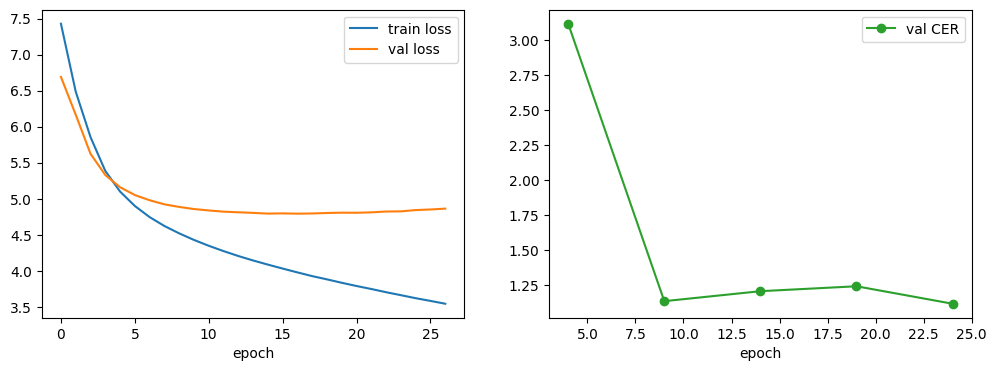

In [8]:
# 訓練曲線
import matplotlib.pyplot as plt

h = np.array(history)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(h[:, 0], label="train loss")
ax1.plot(h[:, 1], label="val loss")
ax1.set_xlabel("epoch")
ax1.legend()
ax2.plot(np.where(~np.isnan(h[:, 2]))[0], h[~np.isnan(h[:, 2]), 2], "o-", label="val CER", color="C2")
ax2.set_xlabel("epoch")
ax2.legend()
plt.show()

## Predictions

In [9]:
PRED_SPLIT = "test"    # train / val / test

vocab = load_vocab()
dataset = SignDataset(PRED_SPLIT, vocab)
loader = DataLoader(dataset, BATCH_SIZE, collate_fn=collate)

model = SignTransformer(len(vocab)).to(DEVICE)
model.load_state_dict(torch.load(CKPT_DIR / "best.pt", map_location=DEVICE))
preds = predict_loader(model, loader, vocab, desc=PRED_SPLIT)
refs = [text for _, text in dataset.rows]

PRED_DIR.mkdir(parents=True, exist_ok=True)
with (PRED_DIR / f"{PRED_SPLIT}_predictions.csv").open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.writer(f)
    writer.writerow(("path", "target", "prediction"))
    writer.writerows((path, ref, pred) for (path, _), ref, pred in zip(dataset.rows, refs, preds))

print(f"{PRED_SPLIT} CER = {char_error_rate(preds, refs):.3f}\n")
for (path, _), ref, pred in list(zip(dataset.rows, refs, preds))[:10]:
    print(f"{path}\n  答案：{ref}\n  預測：{pred}")

load test: 100%|██████████| 2265/2265 [00:14<00:00, 158.13it/s]


test CER = 1.068

2/10/000641_001738_s00.npy
  答案：台鐵445次台東往樹林的普悠瑪號
  預測：台灣各地及澎湖 金門 馬祖
2/10/000641_001738_s01.npy
  答案：昨天晚間9點多行經和平站附近時
  預測：中國時報是 中國際油價格蘭
2/10/000641_001738_s02.npy
  答案：撞到一顆巨大落石
  預測：不過民眾在上班客運送醫院
2/10/000641_001738_s03.npy
  答案：導致1到3節車廂出軌
  預測：而且參加上路
2/10/000641_001738_s04.npy
  答案：所幸沒有翻覆 旅客都平安
  預測：不過行政院長卓榮泰拍板
2/10/000641_001738_s05.npy
  答案：下車走到和平站 換乘區間車北上
  預測：在台南地區的一路段
2/10/000641_001738_s06.npy
  答案：但這起意外也造成台鐵一度雙向不通
  預測：不過民眾在網路上網路
2/10/000641_001738_s07.npy
  答案：緊急搶修後在清晨6點搶通恢復雙線正常行車
  預測：可能會更多人到30萬元
2/10/004522_005398_s00.npy
  答案：花蓮強震 游家5口人在砂卡礑步道
  預測：台灣300000000000000萬元交保
2/10/004522_005398_s01.npy
  答案：遭遇強震 山壁崩塌 經過8天搜索
  預測：有些科技大學校園區域劃半導體及花東南部分


## 評估
CER 在 1 附近時幾乎看不出差別，所以這裡另外算：
- **基準線**：空字串、每句都輸出訓練集最常見的句子、打亂配對。模型至少要贏過它們才算有學到東西。
- **套句 vs 新句**：答案在訓練集出現過的句子 (例如「讀報時間來看到」) 跟沒出現過的分開算，**新句**才代表真正的翻譯能力。
- **去除重複迴圈**：把「中國中國中國…」壓成一次再算 CER，避免少數幾句拉高整體數字。
- **字元精確率 / 召回率**：預測的字有多少出現在答案裡、答案的字有多少被預測到 (不看順序)。

只讀 `PRED_DIR` 裡存好的預測 csv，不用重新跑模型。

In [10]:
import re
import unicodedata
from collections import Counter, defaultdict

LOOP_RE = re.compile(r"(.{1,4}?)\1{2,}")      # 同一段 1~4 字連續出現 3 次以上


def pad(text, width, left=True):
    """依顯示寬度補空白 (中文字佔 2 格)，讓表格對齊。"""
    w = sum(2 if unicodedata.east_asian_width(ch) in "WF" else 1 for ch in str(text))
    space = " " * max(0, width - w)
    return f"{text}{space}" if left else f"{space}{text}"


def table_row(label, values, label_width=24, width=12):
    cells = [pad("" if v is None else (f"{v:.3f}" if isinstance(v, float) else v), width, left=False) for v in values]
    return pad(label, label_width) + "".join(cells)


def clean_repeats(text):
    """「中國中國中國中國」→「中國」"""
    return LOOP_RE.sub(r"\1", text)


def char_prf(preds, refs):
    """不看順序的字元精確率、召回率、F1。"""
    hit = n_pred = n_ref = 0
    for p, r in zip(preds, refs):
        hit += sum((Counter(p) & Counter(r)).values())
        n_pred, n_ref = n_pred + len(p), n_ref + len(r)
    prec, rec = hit / max(1, n_pred), hit / max(1, n_ref)
    return prec, rec, 2 * prec * rec / max(1e-9, prec + rec)


def shuffled(preds, groups=None, seed=SEED):
    """打亂預測跟答案的配對。groups 不是 None 時只在同一組 (同一則新聞) 裡打亂。"""
    rng = random.Random(seed)
    if groups is None:
        out = preds[:]
        rng.shuffle(out)
        return out
    out, by_group = preds[:], defaultdict(list)
    for i, g in enumerate(groups):
        by_group[g].append(i)
    for idx in by_group.values():
        perm = idx[:]
        rng.shuffle(perm)
        for a, b in zip(idx, perm):
            out[a] = preds[b]
    return out


def evaluate(pred_csv, train_csv, verbose=True):
    """回傳評估結果 dict；verbose=True 時印出表格。"""
    with Path(pred_csv).open(encoding="utf-8-sig", newline="") as f:
        rows = list(csv.DictReader(f))
    with Path(train_csv).open(encoding="utf-8-sig", newline="") as f:
        train_freq = Counter(row["text"] for row in csv.DictReader(f))

    paths = [r["path"] for r in rows]
    refs = [r["target"] for r in rows]
    raw = [r["prediction"] for r in rows]
    preds = [clean_repeats(p) for p in raw]
    clips = [p.rsplit("_s", 1)[0] for p in paths]          # 同一則新聞 = 同一個原始 .npy
    seen = [train_freq[r] > 0 for r in refs]
    most_common = train_freq.most_common(1)[0][0]

    def sub(mask):
        idx = [i for i, m in enumerate(mask) if m]
        return [preds[i] for i in idx], [refs[i] for i in idx]

    new_p, new_r = sub([not s for s in seen])
    old_p, old_r = sub(seen)
    res = {
        "n": len(refs),
        "n_new": len(new_r),
        "loop_rate": sum(p != c for p, c in zip(raw, preds)) / len(raw),
        "unique_rate": len(set(raw)) / len(raw),
        "cer_raw": char_error_rate(raw, refs),
        "cer": char_error_rate(preds, refs),
        "cer_seen": char_error_rate(old_p, old_r) if old_r else float("nan"),
        "cer_new": char_error_rate(new_p, new_r) if new_r else float("nan"),
        "prf": char_prf(preds, refs),
        "prf_new": char_prf(new_p, new_r) if new_r else (float("nan"),) * 3,
        "base_empty": 1.0,
        "base_const": char_error_rate([most_common] * len(refs), refs),
        "base_shuffle": char_error_rate(shuffled(preds), refs),
        "base_shuffle_clip": char_error_rate(shuffled(preds, clips), refs),
        "prf_shuffle": char_prf(shuffled(preds), refs),
        "prf_shuffle_clip": char_prf(shuffled(preds, clips), refs),
    }
    if not verbose:
        return res

    print(f"{pred_csv}：{res['n']} 句，其中 {res['n_new']} 句 ({res['n_new'] / res['n']:.0%}) 沒在訓練集出現過")
    print(f"不同的預測：{res['unique_rate']:.0%}，有重複迴圈：{res['loop_rate']:.1%}\n")
    print(table_row("", ["CER", "字元精確率", "字元召回率"]))
    print(table_row("模型 (原始輸出)", [res["cer_raw"]]))
    print(table_row("模型 (去除重複迴圈)", [res["cer"], *res["prf"][:2]]))
    print(table_row("  └ 套句 (訓練集有)", [res["cer_seen"]]))
    print(table_row("  └ 新句 (訓練集沒有)", [res["cer_new"], *res["prf_new"][:2]]))
    print("-" * 60)
    print(table_row("基準：空字串", [res["base_empty"]]))
    print(table_row("基準：固定輸出最常見句", [res["base_const"]]))
    print(table_row("基準：全部打亂配對", [res["base_shuffle"], *res["prf_shuffle"][:2]]))
    print(table_row("基準：同則新聞內打亂", [res["base_shuffle_clip"], *res["prf_shuffle_clip"][:2]]))
    print("\n怎麼看：")
    print("  CER 要低於「固定輸出最常見句」才算贏過亂猜；")
    print("  字元精確率要明顯高於「同則新聞內打亂」，才代表模型讀到的是「這一句」，不只是新聞主題。")
    return res


eval_result = evaluate(PRED_DIR / f"{PRED_SPLIT}_predictions.csv", DATA_DIR / "train.csv")

predictions_m0.5\test_predictions.csv：2265 句，其中 2115 句 (93%) 沒在訓練集出現過
不同的預測：57%，有重複迴圈：6.0%

                                 CER  字元精確率  字元召回率
模型 (原始輸出)                1.068
模型 (去除重複迴圈)            0.997       0.125       0.106
  └ 套句 (訓練集有)            0.411
  └ 新句 (訓練集沒有)          1.024       0.092       0.077
------------------------------------------------------------
基準：空字串                   1.000
基準：固定輸出最常見句         0.988
基準：全部打亂配對             1.079       0.040       0.033
基準：同則新聞內打亂           1.062       0.066       0.056

怎麼看：
  CER 要低於「固定輸出最常見句」才算贏過亂猜；
  字元精確率要明顯高於「同則新聞內打亂」，才代表模型讀到的是「這一句」，不只是新聞主題。


## 實驗 3：比較原本切法 vs 寬鬆切法
步驟：
1. `03split_npy.py` 把 `MARGIN` 改成 0.5 (或 1.0)，part 輸入 `all`，切出 `03segments_m0.5`、`03labels_m0.5`
2. 這個 notebook 最上面把 `EXP_TAG` 改成 `"_m0.5"`，從頭跑到 Predictions (不用跑診斷實驗)
3. 跑下面這格比較

兩邊的影片切分 (train / val / test) 會一樣，因為都是用同樣的 SEED 對同一批子資料夾分組；這格也會檢查測試集是不是同一批句子。

**怎麼判斷**：寬鬆切法的「新句 CER」或「新句字元精確率」明顯變好 → 切點是瓶頸，值得改進 02；幾乎沒變 → 切點不是主要問題，應該先改模型。

In [11]:
EXPERIMENTS = ["", "_m0.5", "_m1"]     # 要比較的 EXP_TAG，還沒跑過的會自動略過

results, test_sets = {}, {}
for tag in EXPERIMENTS:
    pred_csv = Path("predictions" + tag) / f"{PRED_SPLIT}_predictions.csv"
    if not pred_csv.exists():
        print(f"略過 {tag or '(原本)'}：找不到 {pred_csv}")
        continue
    results[tag] = evaluate(pred_csv, Path("data" + tag) / "train.csv", verbose=False)
    with pred_csv.open(encoding="utf-8-sig", newline="") as f:
        test_sets[tag] = {row["path"] for row in csv.DictReader(f)}

if len(set(map(frozenset, test_sets.values()))) > 1:
    print("[注意] 各實驗的測試集句子不完全一樣，比較結果僅供參考")

cols = [
    ("CER", "cer"), ("新句 CER", "cer_new"), ("套句 CER", "cer_seen"),
    ("新句精確率", lambda r: r["prf_new"][0]), ("新句召回率", lambda r: r["prf_new"][1]),
    ("迴圈率", "loop_rate"), ("固定句基準", "base_const"), ("同則打亂基準", "base_shuffle_clip"),
]
print()
print(table_row("實驗", [name for name, _ in cols], label_width=10, width=14))
for tag, r in results.items():
    vals = [(key(r) if callable(key) else r[key]) for _, key in cols]
    print(table_row(tag or "(原本)", vals, label_width=10, width=14))

略過 _m1：找不到 predictions_m1\test_predictions.csv

實驗                 CER      新句 CER      套句 CER    新句精確率    新句召回率        迴圈率    固定句基準  同則打亂基準
(原本)             1.005         1.033         0.413         0.088         0.075         0.062         0.988         1.069
_m0.5              0.997         1.024         0.411         0.092         0.077         0.060         0.988         1.062
